# Universidad Autónoma del Estado de México — Centro Universitario UAEM Zumpango

**Asignatura:** Investigación de Operaciones  
**Práctica 1:** Árbol de Expansión Mínima — Algoritmo de Prim  
**Programa educativo:** Ingeniería en Computación  
**Integrantes:** __________________________________  
**Docente:** __________________________________  
**Periodo:** 2026B

> **Nota:** Este es un caso didáctico creado para la práctica. Los costos son hipotéticos y no representan cotizaciones reales del campus.

## 1. Descripción del problema

Imaginemos que una universidad desea conectar nueve edificios mediante una red de fibra óptica. Esta conexión permitiría compartir información entre áreas, utilizar sensores inteligentes, controlar accesos y enviar datos a un centro de monitoreo. Sin embargo, instalar fibra óptica tiene un costo, y no todos los caminos entre edificios cuestan lo mismo.

Para resolver esta situación se proponen **18 corredores posibles**, cada uno con un costo de instalación. La pregunta que buscamos responder es: **¿qué conexiones conviene construir para que todos los edificios estén comunicados y se gaste la menor cantidad posible?**

Representaremos el problema mediante un **grafo**: cada letra será un edificio o *nodo*; cada línea será un corredor o *arista*; y cada número señalará cuánto cuesta construir ese enlace, en miles de pesos. Utilizaremos el **algoritmo de Prim**, que comienza en un edificio y va agregando, paso a paso, la conexión más barata que permita alcanzar un edificio todavía no incorporado.

La finalidad no es conectar todos los edificios directamente con Rectoría, sino formar una red completa con el **menor costo total**, sin conexiones repetidas que generen ciclos. En este ejercicio comenzaremos en **A (Rectoría)** y explicaremos por qué se toma cada decisión.

## 2. Formulación matemática

Sea $G=(V,E)$ un grafo conexo no dirigido, con $|V|=9$, $|E|=18$ y peso $c_{ij}$ para cada corredor.

Definimos $x_{ij}\in\{0,1\}$: vale 1 si se instala la conexión $(i,j)$ y 0 en caso contrario.

$$\min Z=\sum_{(i,j)\in E}c_{ij}x_{ij}$$

Sujeto a que la solución forme un árbol que abarque los nueve nodos: sea conexa, carezca de ciclos y contenga exactamente $|V|-1=8$ aristas. Una forma de expresar conectividad es exigir que para todo subconjunto propio no vacío $S\subset V$ exista al menos una arista seleccionada cruzando el corte $(S,V\setminus S)$:

$$\sum_{(i,j)\in\delta(S)}x_{ij}\geq 1,\quad \varnothing\ne S\subsetneq V.$$

**Regla de Prim:** dado el conjunto de nodos visitados $S$, seleccionar la arista de **menor peso entre las que cruzan el corte** desde $S$ hacia un nodo fuera de $S$. Repetir hasta visitar todos los edificios.

En caso de empate, se ordenarán las aristas lexicográficamente para garantizar resultados reproducibles.

## 3. Bibliotecas utilizadas

Antes de resolver el ejercicio, importamos algunas herramientas de Python. **NetworkX** permite almacenar la red de edificios y comprobar al final que el resultado es un árbol de expansión mínima. **Matplotlib** se utiliza para dibujar las conexiones y observar cómo cambia la red en cada paso. **Pandas** organiza las alternativas y los resultados en tablas fáciles de leer.

Aunque utilizamos NetworkX para representar y verificar la red, **las decisiones del algoritmo de Prim se calculan en nuestro propio código**. De esta forma podemos observar todo el procedimiento y no solamente el resultado final.

In [1]:
import networkx as nx
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from pathlib import Path
plt.rcParams.update({'font.size': 10})
print('Bibliotecas preparadas para ejecutar Prim.')

Bibliotecas preparadas para ejecutar Prim.


## 4. Registro de edificios y conexiones disponibles

En esta sección escribimos los datos que describen la red. Primero asignamos una letra y un nombre a cada edificio; después registramos los **18 enlaces posibles** con su costo. Por ejemplo, una conexión con peso 8 representa un gasto hipotético de **8 mil pesos**.

También establecemos posiciones para dibujar los edificios. Estas coordenadas solo ayudan a que el esquema sea claro: **no son distancias reales ni modifican los costos**. Finalmente, el programa comprueba que tenemos nueve edificios, 18 enlaces y que, con las alternativas disponibles, es posible llegar de un edificio a cualquier otro.

In [2]:
edificios = {
 'A':'Rectoría', 'B':'Biblioteca', 'C':'Laboratorio IA',
 'D':'Centro de Datos', 'E':'Aulas Norte', 'F':'Taller IoT',
 'G':'Seguridad', 'H':'Auditorio', 'I':'Energía'
}
aristas = [
 ('A','B',8),('A','C',12),('A','D',14),('B','C',7),('B','E',11),
 ('C','D',6),('C','F',13),('D','F',9),('D','G',15),('E','F',5),
 ('E','H',17),('F','G',4),('F','H',10),('G','I',8),('H','I',6),
 ('B','H',18),('C','G',16),('E','I',19)
]
pos = {'A':(0,3),'B':(2,4),'C':(4,3),'D':(6,4),'E':(1,1),
       'F':(4,1),'G':(7,1),'H':(2,-1),'I':(6,-1)}
G = nx.Graph()
G.add_nodes_from(edificios.keys())
G.add_weighted_edges_from(aristas)
assert G.number_of_nodes()==9 and G.number_of_edges()==18 and nx.is_connected(G)
print('Edificios:',len(edificios),'| Corredores:',len(aristas))
display(pd.DataFrame(aristas,columns=['Origen','Destino','Costo (miles MXN)']))

Edificios: 9 | Corredores: 18


,Origen,Destino,Costo (miles MXN)
0,A,B,8
1,A,C,12
2,A,D,14
3,B,C,7
4,B,E,11
5,C,D,6
6,C,F,13
7,D,F,9
8,D,G,15
9,E,F,5


## 5. Representación gráfica de la red original

La primera gráfica muestra **todas las conexiones que podríamos construir**, antes de aplicar Prim. Cada círculo representa un edificio identificado por su letra; las líneas representan los corredores disponibles; y los números muestran los costos en miles de pesos.

Para entender las siguientes gráficas, utilizaremos la misma representación durante toda la práctica: los enlaces que todavía son alternativas aparecen en **gris**, los que ya forman parte de nuestra solución se resaltan en **verde** y la conexión que acabamos de seleccionar se distingue en **naranja**. Los nodos incorporados al árbol también cambian de color.

Así podremos comparar la red original con la red que se va formando, sin perder de vista las conexiones que aún podemos elegir.

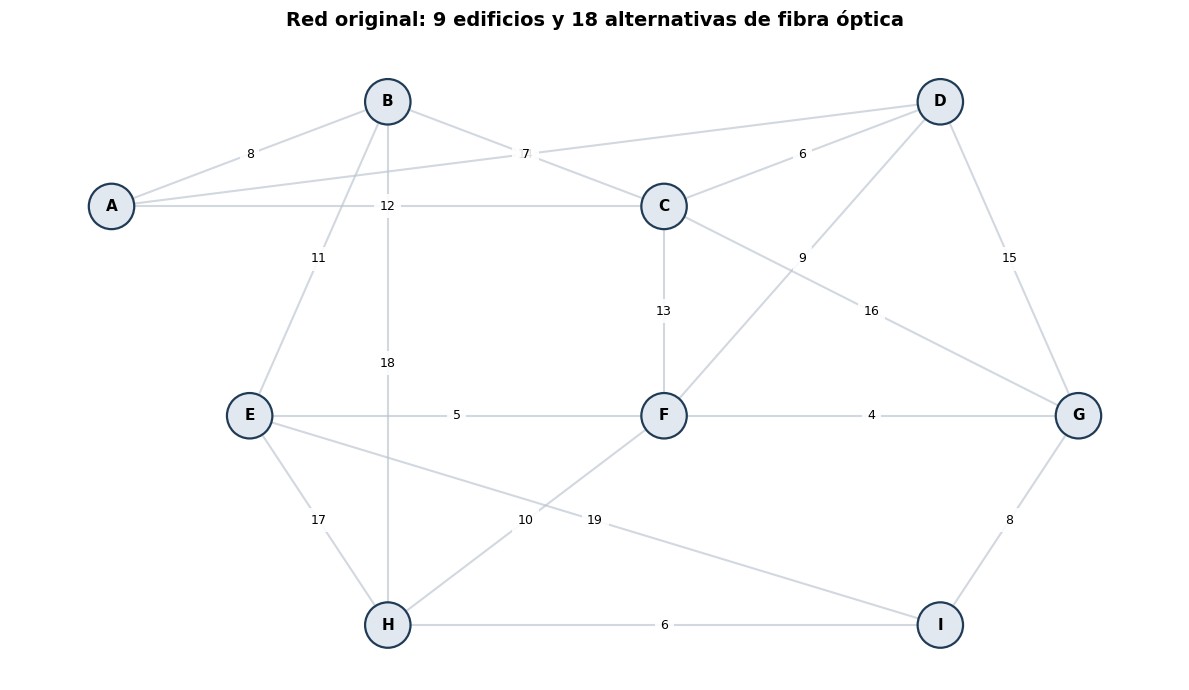

In [3]:
def dibujar_prim(seleccionadas=None, visitados=None, nueva=None, titulo='Red de candidatos', ruta_guardado=None):
    seleccionadas = seleccionadas or []
    visitados = set() if visitados is None else set(visitados)
    fig, ax = plt.subplots(figsize=(12,7))
    nx.draw_networkx_edges(G, pos, ax=ax, edge_color='#bac3cf', width=1.5, alpha=.65)
    nx.draw_networkx_nodes(G,pos,ax=ax,nodelist=list(G.nodes),node_color=[('#70c4e5' if v in visitados else '#e2e8f0') for v in G.nodes],edgecolors='#203b56',node_size=1070,linewidths=1.6)
    nx.draw_networkx_labels(G,pos,ax=ax,font_weight='bold',font_size=11)
    nx.draw_networkx_edge_labels(G,pos,ax=ax,edge_labels=nx.get_edge_attributes(G,'weight'),font_size=9,bbox={'facecolor':'white','alpha':.88,'edgecolor':'none'},rotate=False)
    if seleccionadas:
        nx.draw_networkx_edges(G,pos,ax=ax,edgelist=[(u,v) for u,v,w in seleccionadas],edge_color='#09866c',width=4.1)
    if nueva:
        nx.draw_networkx_edges(G,pos,ax=ax,edgelist=[(nueva[0],nueva[1])],edge_color='#f59e0b',width=5.3)
    ax.set_title(titulo,fontsize=14,fontweight='bold',pad=15)
    ax.axis('off')
    fig.tight_layout()
    if ruta_guardado:fig.savefig(ruta_guardado,dpi=170,bbox_inches='tight')
    plt.show()

dibujar_prim(titulo='Red original: 9 edificios y 18 alternativas de fibra óptica')

## 6. Inicio y funcionamiento del algoritmo de Prim

Comenzaremos en el edificio **A — Rectoría**. Al inicio, este es el único edificio que pertenece a nuestra nueva red; los otros ocho están pendientes de conexión.

En cada paso seguimos la misma regla:

1. Revisamos las conexiones que salen de **cualquier edificio ya incorporado** hacia uno que todavía no pertenece a la red.
2. Comparamos los costos de esas conexiones y elegimos **la de menor costo**.
3. Agregamos el enlace y el nuevo edificio a nuestra red, y actualizamos el costo acumulado.
4. Repetimos el procedimiento hasta incorporar los nueve edificios.

Es importante no confundir Prim con la idea de elegir siempre la línea más barata de toda la gráfica. Una conexión solo puede seleccionarse si **une la red que ya construimos con un nodo nuevo**. Si sus dos extremos están fuera o sus dos extremos ya están dentro, no cumple esa función en ese momento.

El código siguiente prepara un registro de cada decisión y dibuja el estado de la red. Como empezamos con un edificio y queremos conectar nueve, necesitaremos exactamente **ocho pasos**.

Nodo de origen: A — Rectoría


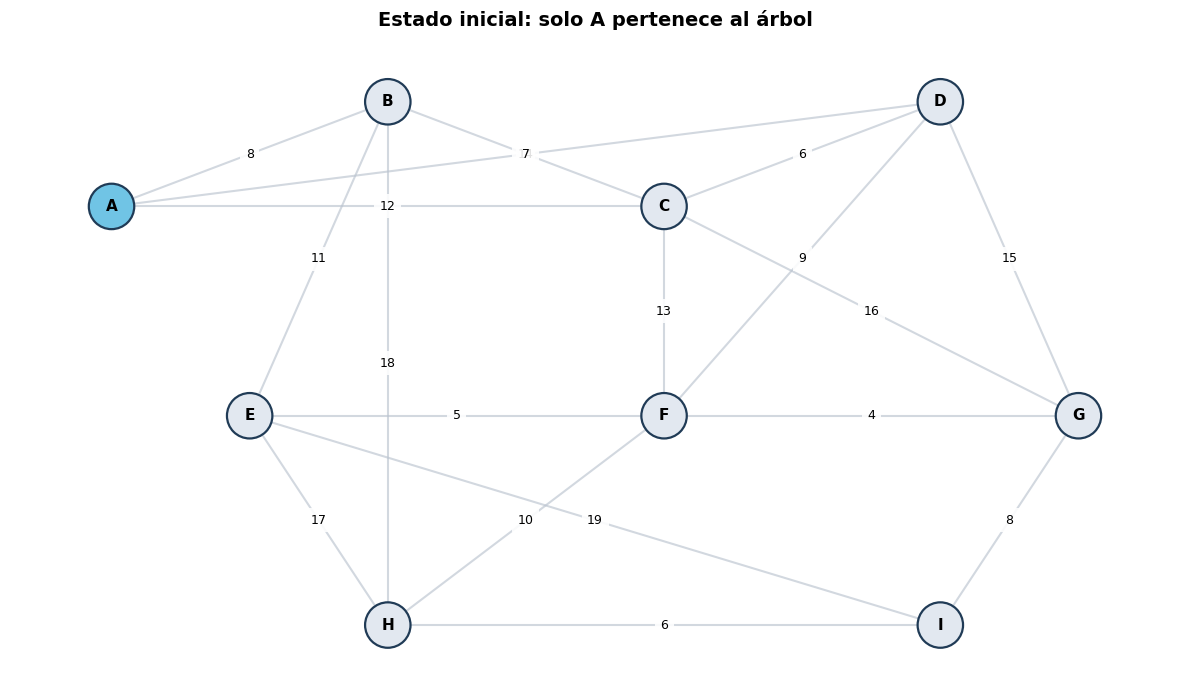

In [4]:
visitados = {'A'}
seleccionadas = []
bitacora = []
costo_acumulado = 0

def ejecutar_paso_prim(numero):
    global costo_acumulado
    candidatas=[]
    for u,v,w in aristas:
        if (u in visitados) != (v in visitados):
            candidatas.append((w,min(u,v),max(u,v),u,v))
    if not candidatas:
        raise RuntimeError('No hay una conexión posible. Revisar conectividad.')
    candidatas.sort()
    costo,_,_,u,v = candidatas[0]
    nuevo = v if u in visitados else u
    previo = sorted(visitados)
    visitados.add(nuevo)
    seleccionadas.append((u,v,costo))
    costo_acumulado += costo
    bitacora.append({'Paso':numero,'Nodos previos':','.join(previo),
      'Conexión elegida':f'{u}-{v}','Nuevo nodo':nuevo,
      'Costo':costo,'Costo acumulado':costo_acumulado,
      'Visitados':','.join(sorted(visitados))})
    print('Paso',numero,'| visitados antes:',previo)
    print('Candidatas (arista, costo):', [(f'{a}-{b}',w) for w,a,b,_,_ in candidatas])
    print('Se elige:',f'{u}-{v}','| costo:',costo,'mil MXN | nuevo nodo:',nuevo)
    print('Costo acumulado:',costo_acumulado,'mil MXN')
    dibujar_prim(seleccionadas,visitados,(u,v,costo),
      f'Prim · paso {numero}/8 · se agrega {u}-{v} ({costo} mil) · acumulado {costo_acumulado} mil MXN')
    return (u,v,costo)

print('Nodo de origen: A — Rectoría')
dibujar_prim(visitados=visitados,titulo='Estado inicial: solo A pertenece al árbol')

### Paso 1 — De Rectoría (A) a Biblioteca (B)

Al principio únicamente tenemos conectado **A**, por lo que comparamos los corredores que parten de ese edificio: **A–B (8)**, **A–C (12)** y **A–D (14)**, todos en miles de pesos.

La alternativa de menor costo es **A–B**, que vale **8 mil pesos**. Por eso incorporamos la Biblioteca (B) al árbol. Ahora tenemos dos edificios conectados, y el gasto acumulado es de **8 mil pesos**.

La siguiente celda muestra las alternativas consideradas y dibuja el primer enlace seleccionado.

Paso 1 | visitados antes: ['A']
Candidatas (arista, costo): [('A-B', 8), ('A-C', 12), ('A-D', 14)]
Se elige: A-B | costo: 8 mil MXN | nuevo nodo: B
Costo acumulado: 8 mil MXN


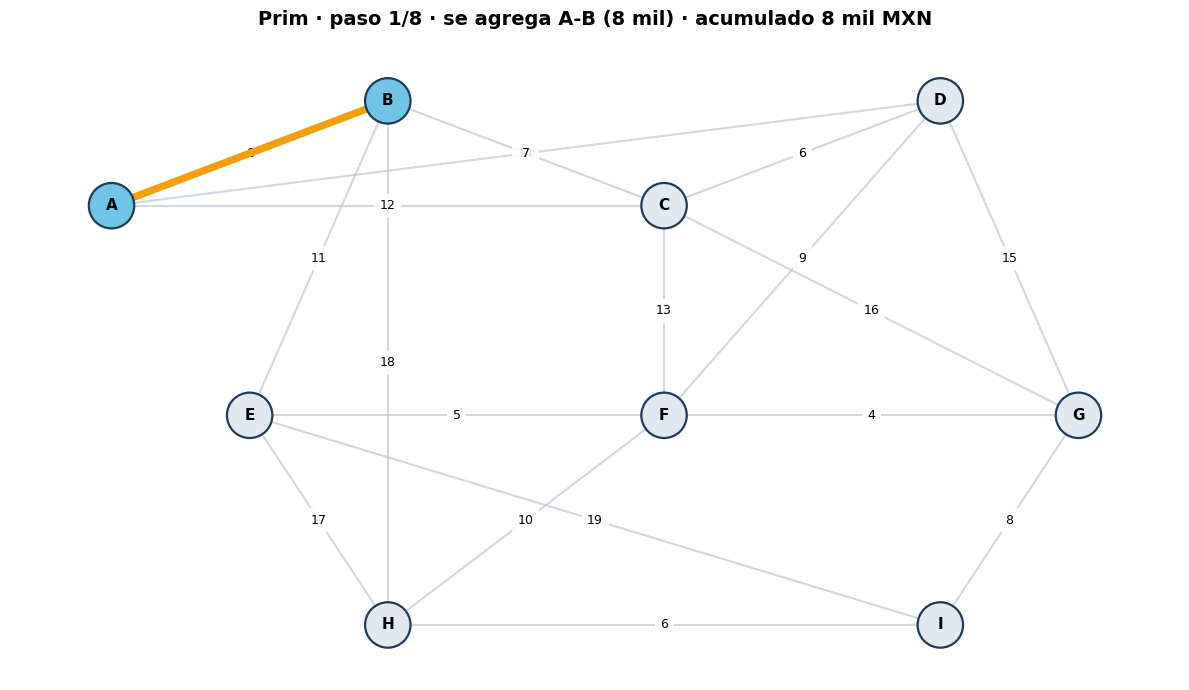

In [5]:
conexion_1 = ejecutar_paso_prim(1)

### Paso 2 — De Biblioteca (B) a Laboratorio IA (C)

Ahora nuestra red contiene **A y B**. Ya no buscamos únicamente conexiones desde Rectoría: revisamos todas las que salen de **cualquiera de estos dos edificios** hacia uno nuevo. Entre ellas están **A–C (12)**, **A–D (14)**, **B–C (7)**, **B–E (11)** y **B–H (18)**.

El menor costo es **B–C (7)**, así que incorporamos el Laboratorio IA (C). El costo acumulado pasa de **8 a 15 mil pesos**. Observa que no elegimos una conexión entre A y B porque ambos ya pertenecen al árbol.

Paso 2 | visitados antes: ['A', 'B']
Candidatas (arista, costo): [('B-C', 7), ('B-E', 11), ('A-C', 12), ('A-D', 14), ('B-H', 18)]
Se elige: B-C | costo: 7 mil MXN | nuevo nodo: C
Costo acumulado: 15 mil MXN


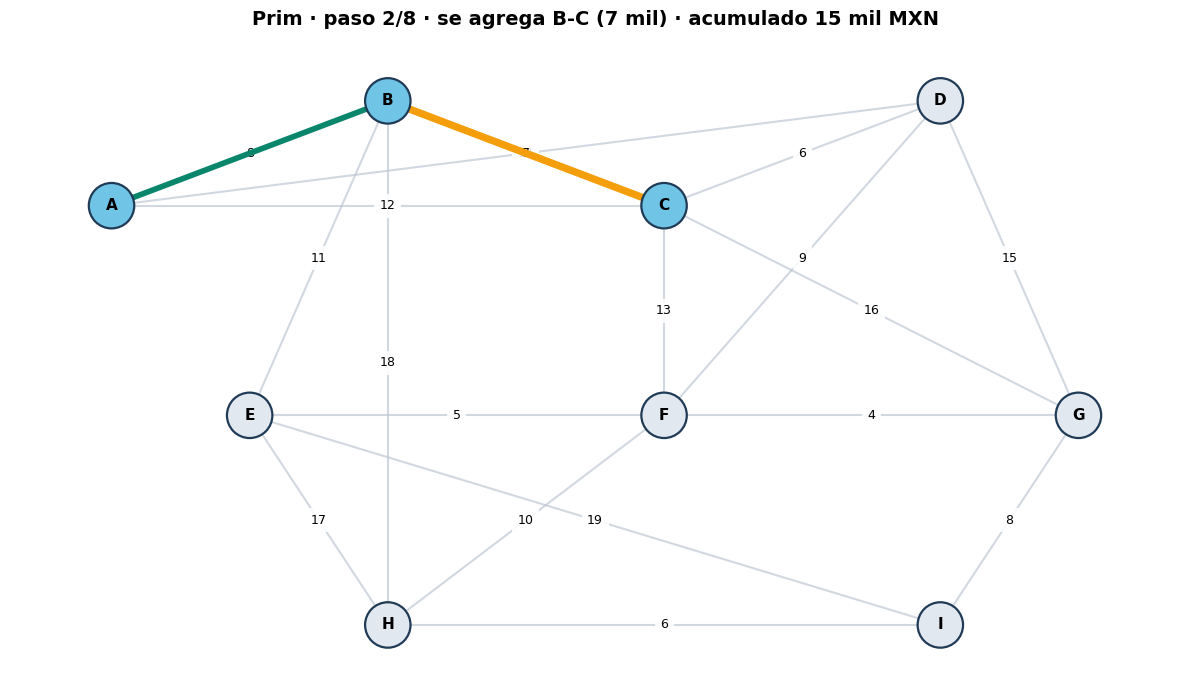

In [6]:
conexion_2 = ejecutar_paso_prim(2)

### Paso 3 — De Laboratorio IA (C) a Centro de Datos (D)

Con **A, B y C** conectados, aparece una nueva alternativa: **C–D**, que cuesta **6 mil pesos**. Este valor es menor que los demás enlaces disponibles que unen nuestra red con un edificio pendiente.

Por esa razón seleccionamos **C–D** e incorporamos el Centro de Datos (D). El costo acumulado aumenta de **15 a 21 mil pesos**. La red crece sin desconectar ningún edificio ni formar un ciclo.

Paso 3 | visitados antes: ['A', 'B', 'C']
Candidatas (arista, costo): [('C-D', 6), ('B-E', 11), ('C-F', 13), ('A-D', 14), ('C-G', 16), ('B-H', 18)]
Se elige: C-D | costo: 6 mil MXN | nuevo nodo: D
Costo acumulado: 21 mil MXN


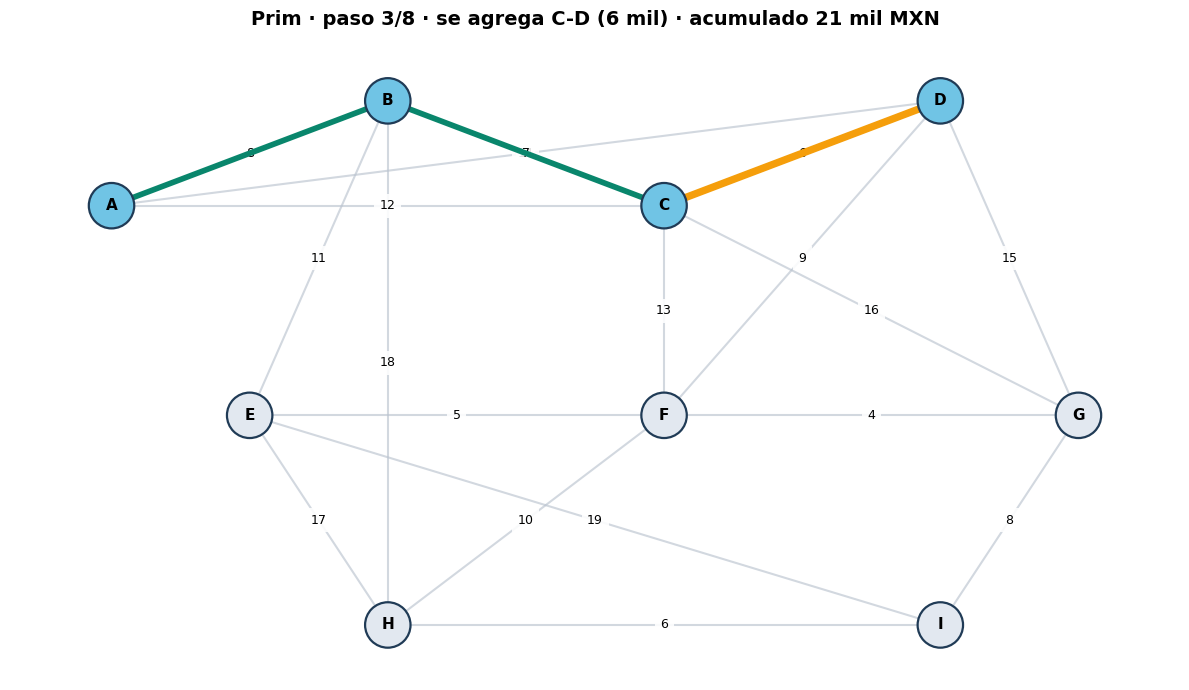

In [7]:
conexion_3 = ejecutar_paso_prim(3)

### Paso 4 — De Centro de Datos (D) a Taller IoT (F)

En este momento ya están conectados **A, B, C y D**. Buscamos la opción más económica para llegar a alguno de los edificios que faltan. La conexión **D–F** cuesta **9 mil pesos** y es la opción elegible de menor costo.

Aunque más adelante veremos un enlace **F–G de solo 4 mil pesos**, todavía no podemos seleccionarlo: **ni F ni G forman parte de la red actual**. Prim exige que cada conexión nueva parta de un edificio que ya esté incorporado.

Elegimos entonces **D–F**, agregamos el Taller IoT (F) y acumulamos **30 mil pesos**.

Paso 4 | visitados antes: ['A', 'B', 'C', 'D']
Candidatas (arista, costo): [('D-F', 9), ('B-E', 11), ('C-F', 13), ('D-G', 15), ('C-G', 16), ('B-H', 18)]
Se elige: D-F | costo: 9 mil MXN | nuevo nodo: F
Costo acumulado: 30 mil MXN


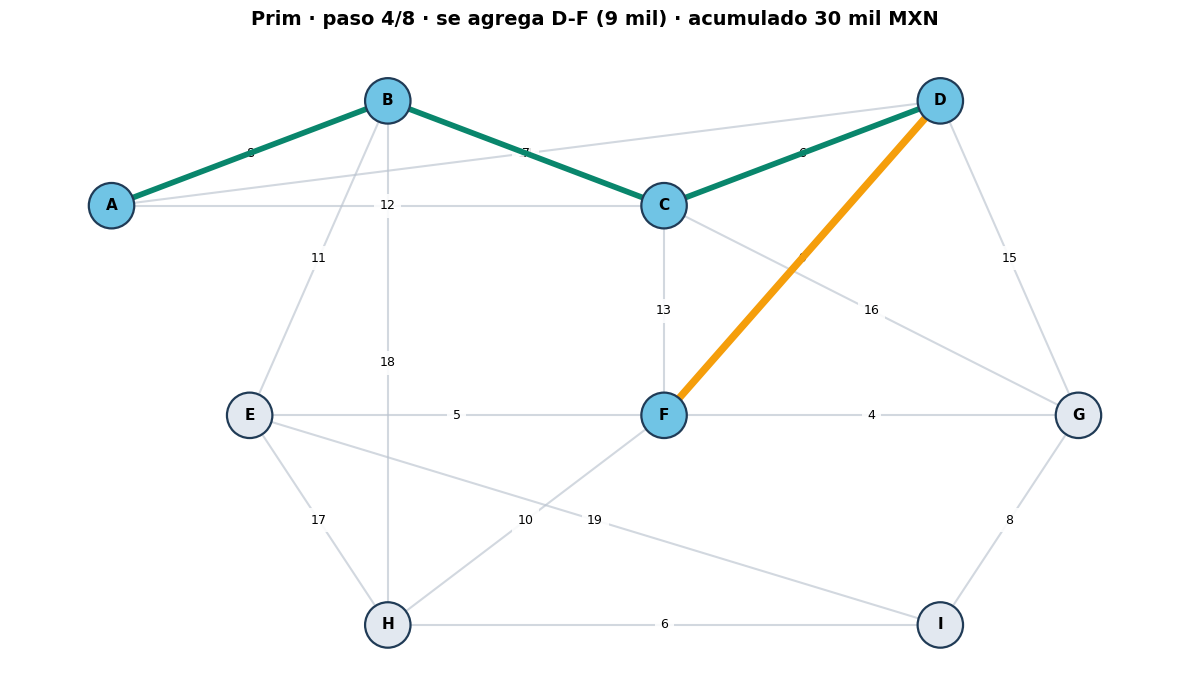

In [8]:
conexion_4 = ejecutar_paso_prim(4)

### Paso 5 — De Taller IoT (F) a Seguridad (G)

Después de conectar el Taller IoT (F), ya podemos considerar sus enlaces hacia otros edificios. Entre ellos aparece **F–G**, cuyo costo es de **4 mil pesos**.

Esta es ahora la alternativa más económica que une la red construida con un edificio nuevo, por lo que agregamos **G (Seguridad)**. Nuestro costo acumulado pasa de **30 a 34 mil pesos**.

Este paso muestra por qué las opciones disponibles cambian conforme crece el árbol: un enlace que antes no era válido puede convertirse en la mejor elección después de incorporar uno de sus extremos.

Paso 5 | visitados antes: ['A', 'B', 'C', 'D', 'F']
Candidatas (arista, costo): [('F-G', 4), ('E-F', 5), ('F-H', 10), ('B-E', 11), ('D-G', 15), ('C-G', 16), ('B-H', 18)]
Se elige: F-G | costo: 4 mil MXN | nuevo nodo: G
Costo acumulado: 34 mil MXN


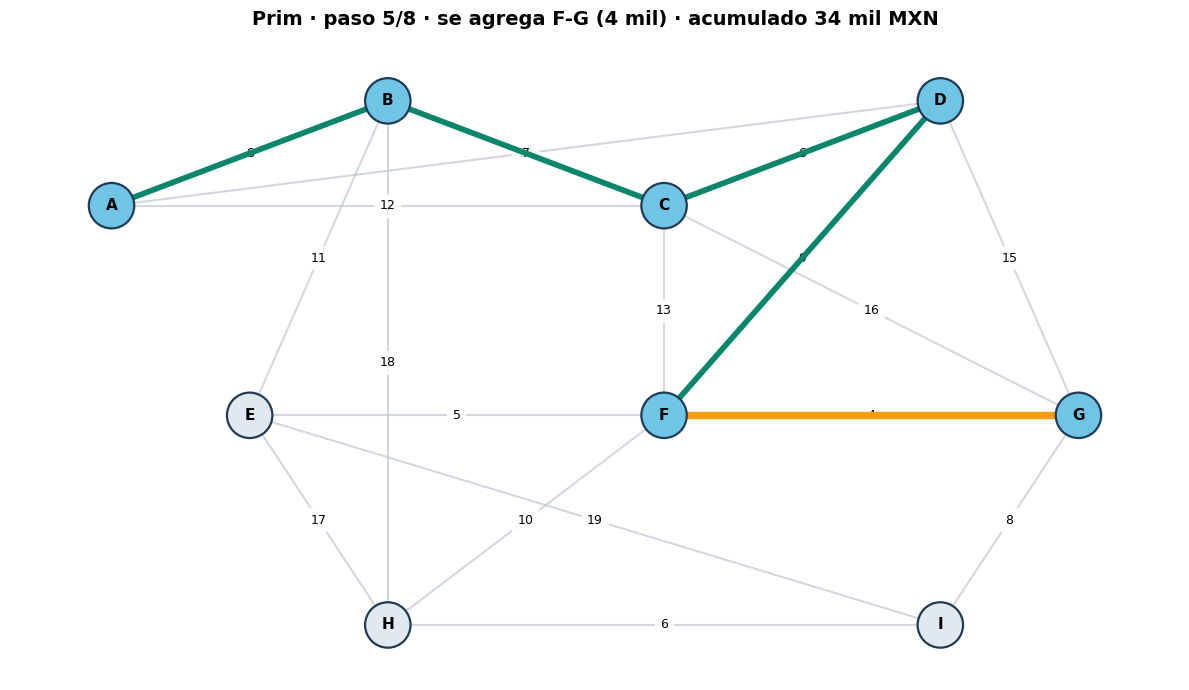

In [9]:
conexion_5 = ejecutar_paso_prim(5)

### Paso 6 — De Taller IoT (F) a Aulas Norte (E)

Ya tenemos conectados **A, B, C, D, F y G**. Para continuar, comparamos los corredores que conducen a los tres edificios pendientes: **E, H e I**.

El enlace **E–F (5)** es el más barato de los que podemos utilizar en este momento. Aunque en la lista de datos aparece escrito como E–F, esto no significa que debamos empezar desde E: **la conexión es de doble sentido**, y F ya pertenece al árbol.

Al incorporarlo, Aulas Norte (E) se une a la red y el costo acumulado pasa de **34 a 39 mil pesos**.

Paso 6 | visitados antes: ['A', 'B', 'C', 'D', 'F', 'G']
Candidatas (arista, costo): [('E-F', 5), ('G-I', 8), ('F-H', 10), ('B-E', 11), ('B-H', 18)]
Se elige: E-F | costo: 5 mil MXN | nuevo nodo: E
Costo acumulado: 39 mil MXN


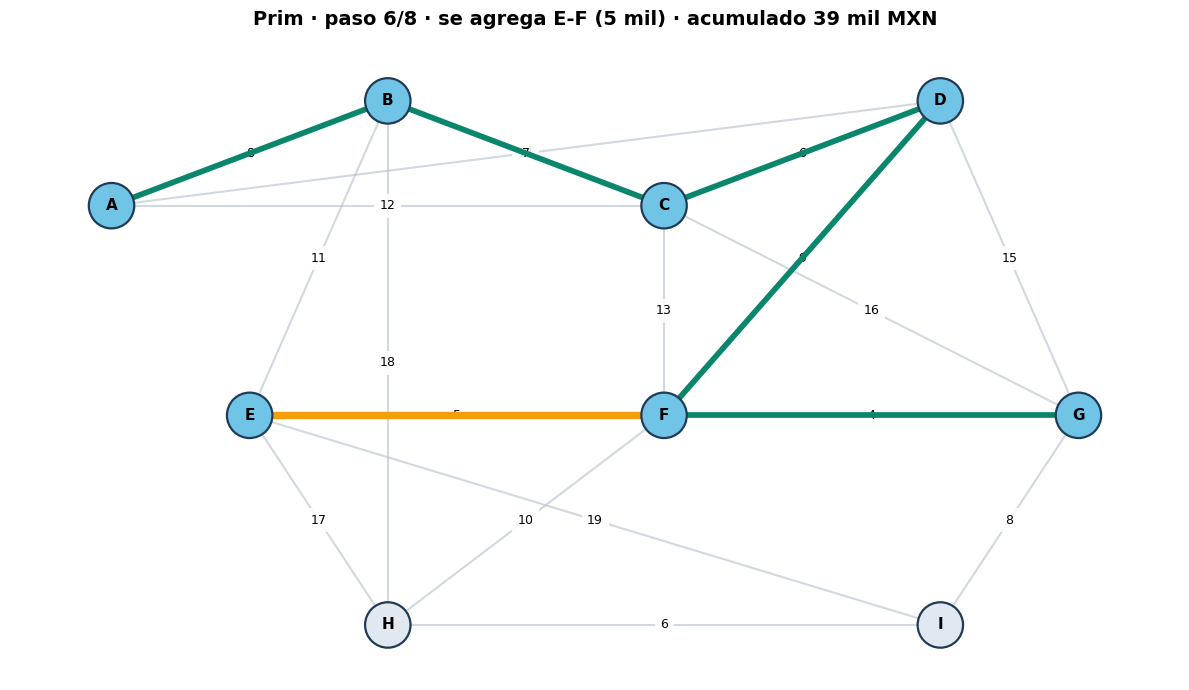

In [10]:
conexion_6 = ejecutar_paso_prim(6)

### Paso 7 — De Seguridad (G) a Energía (I)

Después del paso anterior, únicamente faltan los edificios **H (Auditorio)** e **I (Energía)**. Revisamos las conexiones disponibles desde la red actual hacia esos edificios.

El enlace **G–I** cuesta **8 mil pesos**, menos que las otras alternativas elegibles en este momento. Por eso conectamos el edificio de Energía (I) desde Seguridad (G).

El gasto acumulado aumenta de **39 a 47 mil pesos**. Solo queda un edificio pendiente para completar la red.

Paso 7 | visitados antes: ['A', 'B', 'C', 'D', 'E', 'F', 'G']
Candidatas (arista, costo): [('G-I', 8), ('F-H', 10), ('E-H', 17), ('B-H', 18), ('E-I', 19)]
Se elige: G-I | costo: 8 mil MXN | nuevo nodo: I
Costo acumulado: 47 mil MXN


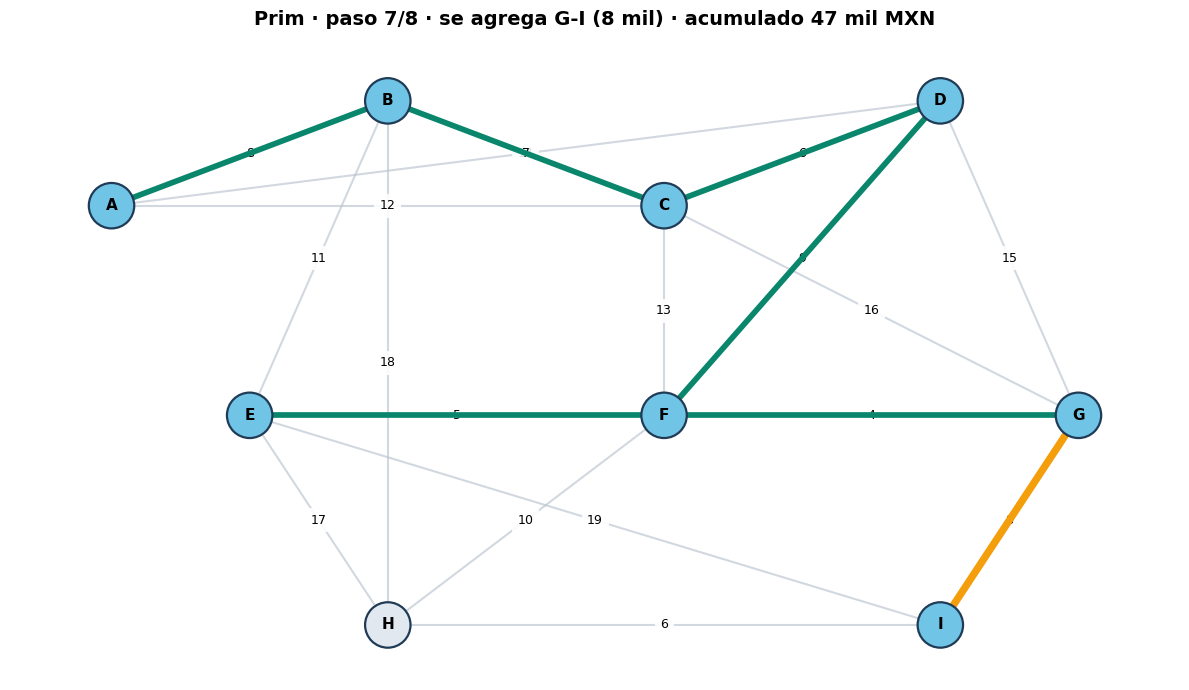

In [11]:
conexion_7 = ejecutar_paso_prim(7)

### Paso 8 — De Energía (I) a Auditorio (H)

El único edificio que falta es **H (Auditorio)**. Ahora podemos alcanzarlo mediante varios corredores, pero **H–I** tiene el menor costo: **6 mil pesos**.

Elegimos ese enlace y conectamos el Auditorio con Energía (I). Con esto, **los nueve edificios quedan comunicados por ocho conexiones**, y el gasto acumulado llega a **53 mil pesos**.

El procedimiento termina aquí porque ya no quedan edificios sin incorporar. Añadir otra conexión no es necesario para lograr el objetivo de un árbol de expansión mínima.

Paso 8 | visitados antes: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'I']
Candidatas (arista, costo): [('H-I', 6), ('F-H', 10), ('E-H', 17), ('B-H', 18)]
Se elige: H-I | costo: 6 mil MXN | nuevo nodo: H
Costo acumulado: 53 mil MXN


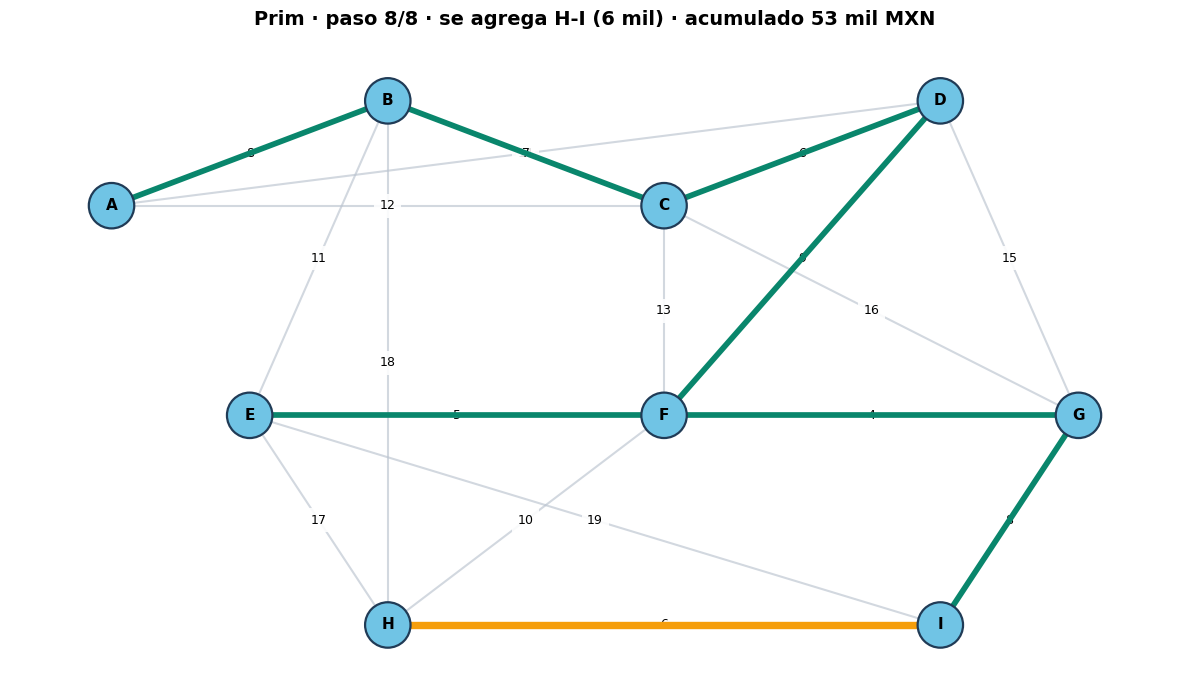

In [12]:
conexion_8 = ejecutar_paso_prim(8)

## 7. Resumen del procedimiento y comprobación del resultado

Después de ejecutar los ocho pasos, el programa reúne todas las decisiones en una tabla. Ahí podemos revisar qué enlace se eligió en cada momento, qué edificio se agregó, cuánto costó esa conexión y cómo aumentó el gasto total.

También comprobamos tres aspectos importantes: **(1)** los nueve edificios están conectados, **(2)** se utilizaron exactamente ocho enlaces y no existen ciclos, y **(3)** el costo calculado coincide con el que obtiene NetworkX al resolver el mismo problema de manera independiente.

Esta verificación sirve para confirmar que nuestra elección no solamente forma una red válida, sino que también alcanza el **costo mínimo esperado**. Finalmente se dibuja el árbol completo y se guarda la imagen del resultado.

,Paso,Nodos previos,Conexión elegida,Nuevo nodo,Costo,Costo acumulado,Visitados
0,1,A,A-B,B,8,8,"A,B"
1,2,"A,B",B-C,C,7,15,"A,B,C"
2,3,"A,B,C",C-D,D,6,21,"A,B,C,D"
3,4,"A,B,C,D",D-F,F,9,30,"A,B,C,D,F"
4,5,"A,B,C,D,F",F-G,G,4,34,"A,B,C,D,F,G"
5,6,"A,B,C,D,F,G",E-F,E,5,39,"A,B,C,D,E,F,G"
6,7,"A,B,C,D,E,F,G",G-I,I,8,47,"A,B,C,D,E,F,G,I"
7,8,"A,B,C,D,E,F,G,I",H-I,H,6,53,"A,B,C,D,E,F,G,H,I"


Árbol de expansión mínima válido: True
Número de corredores seleccionados: 8
Costo mínimo: 53 mil MXN = $53,000 MXN
Coincidencia de costo con NetworkX: True


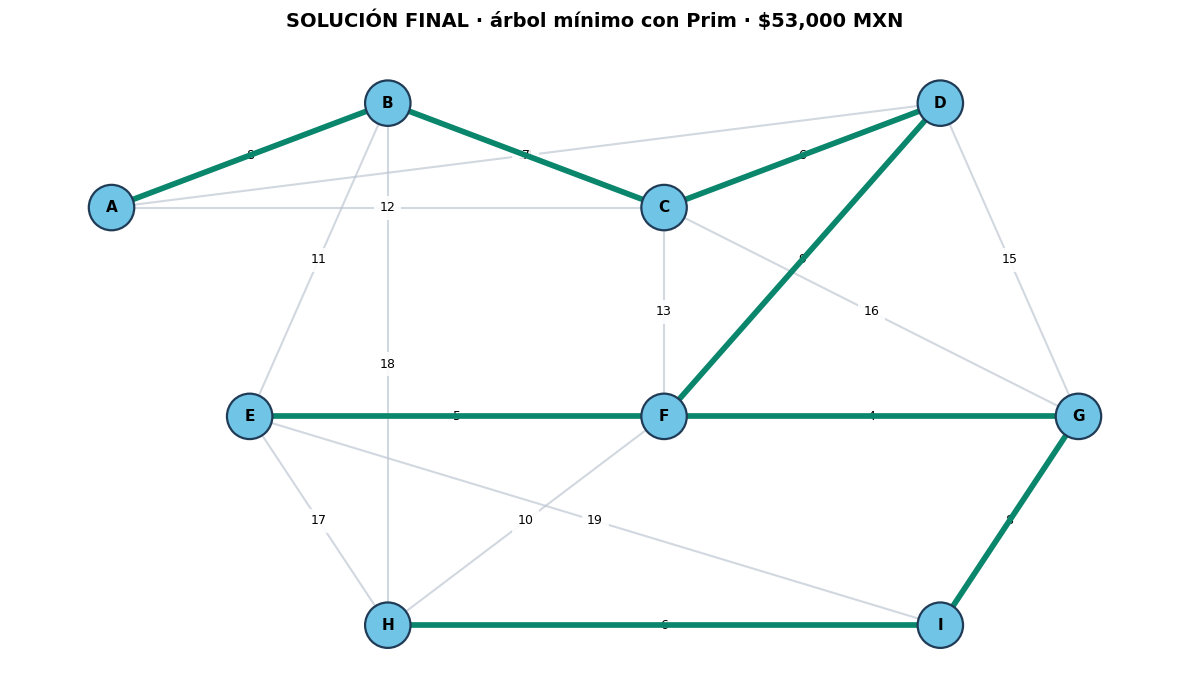

In [13]:
tabla = pd.DataFrame(bitacora)
display(tabla)
T = nx.Graph()
T.add_nodes_from(G.nodes)
T.add_weighted_edges_from(seleccionadas)
referencia = nx.minimum_spanning_tree(G,algorithm='prim',weight='weight')
assert nx.is_tree(T)
assert len(seleccionadas) == len(G.nodes)-1
assert costo_acumulado == referencia.size(weight='weight')
print('Árbol de expansión mínima válido:',nx.is_tree(T))
print('Número de corredores seleccionados:',len(seleccionadas))
print('Costo mínimo:',costo_acumulado,'mil MXN =',f'${costo_acumulado*1000:,.0f} MXN')
print('Coincidencia de costo con NetworkX:',costo_acumulado == referencia.size(weight='weight'))
dibujar_prim(seleccionadas,visitados, titulo='SOLUCIÓN FINAL · árbol mínimo con Prim · $53,000 MXN',
            ruta_guardado='Practica_1_Expansion_Minima_Prim_resultado.png')

## 8. Interpretación de los resultados

Al terminar el algoritmo, la red propuesta queda formada por estas ocho conexiones: **A–B (8), B–C (7), C–D (6), D–F (9), F–G (4), E–F (5), G–I (8) y H–I (6)**. Los valores están expresados en miles de pesos, así que sumarlos da **53 mil pesos, equivalentes a $53,000 MXN**.

Lo importante es que **todos los edificios pueden comunicarse**, aunque algunos no estén conectados directamente entre sí. Por ejemplo, para llegar desde Rectoría (A) hasta Energía (I) podemos recorrer varios enlaces de la red. Esto permite cumplir el objetivo utilizando únicamente ocho corredores.

**¿Por qué podemos afirmar que es una solución mínima?** Porque en cada paso seleccionamos el enlace de menor costo que une los edificios ya conectados con uno que todavía falta. Esta regla corresponde al algoritmo de Prim y permite construir un árbol de expansión mínima cuando la red es conexa. Además, el programa compara nuestro costo con el resultado independiente de NetworkX.

**¿Qué significa esto para una red real?** Que, bajo los costos y condiciones del ejercicio, esta sería la alternativa más económica para comunicar los edificios. No obstante, una red en forma de árbol tiene una limitación importante: **si se rompe un enlace, algunos edificios pueden quedar incomunicados**. En una instalación real habría que valorar conexiones de respaldo, mantenimiento y disponibilidad del servicio. Esos requisitos no están incluidos en este problema, que se concentra exclusivamente en minimizar el costo de conexión.

## 9. Conclusiones

**Conclusión individual (ejemplo para adaptar):** Durante esta práctica comprendí cómo funciona el algoritmo de Prim al resolver un problema de conexión entre edificios. Al observar las gráficas de cada paso, pude identificar que no basta con seleccionar la conexión más barata de toda la red; es necesario que esa conexión salga de un edificio que ya esté incorporado y permita llegar a uno nuevo. También entendí cómo se calcula el costo acumulado hasta obtener la solución final.

**Conclusión del equipo (propuesta para adaptar):** Mediante la aplicación del algoritmo de Prim se logró diseñar una red que conecta nueve edificios utilizando ocho enlaces y un costo mínimo total de **$53,000 MXN**. El procedimiento se explicó paso a paso y se comprobó con una herramienta independiente, lo que permite justificar cada conexión seleccionada. Como posible mejora para un caso real, se recomienda estudiar la incorporación de enlaces de respaldo, aunque esto implique aumentar el presupuesto.

## 10. Preguntas para reflexionar

1. ¿Por qué es necesario que la red original permita llegar de un edificio a cualquier otro para que Prim pueda conectar los nueve?
2. ¿Por qué en el paso 4 no podemos elegir todavía el enlace F–G, aunque cuesta solamente 4 mil pesos?
3. Si comenzáramos en Energía (I) en vez de Rectoría (A), ¿cambiaría el orden de las conexiones? ¿Tendría que cambiar el costo mínimo?
4. ¿Qué modificaciones haríamos si la universidad necesitara que la red siguiera funcionando cuando se interrumpiera una conexión?

**Nota:** Las tablas y las gráficas se generan al ejecutar las celdas del cuaderno en orden.